# pyspan, FLUPS: compare datasets

Example on 240619 (ZsOMe in hexane), data as in the edyx FLUPS example. `Overlay` compares
datasets: first vs last run (sample degradation), and before/after the PCF.

For tools that make decisions, the principle is: a decisions cell holds the literal printed by
"Done", and a plain data step uses it without the widget (see `ta_reject_t0.ipynb`).
`Overlay` only displays, so it needs no such cell.

Needs `%matplotlib widget` (JupyterLab or VS Code, with `ipympl`).

In [20]:
%matplotlib widget
from pathlib import Path

import numpy as np

from edyx.fana import despike_median, fluo_wl, pcf_correct
from edyx.io import load_txt, stack_traces
from edyx.utils import between
from edyx.tana import avg_scans, shift_trace, subtract_pre_t0
from edyx.tana import crop
from edyx.plot import plot_maps
from pyspan import Overlay

## Parameters and read

Every value marked **choice** is a scientific decision copied from the edyx example: check it
for your own data.

In [2]:
data_dir = Path("../../edyx/examples/data")  # edyx example data, see its README.md
runs = [5, 6, 9, 10]  # choice: the "early" scans of runs 05-12 (the sample degrades)
fnames = [f"240619_run{i:02d}.txt" for i in runs]

t_bg = -1.4             # ps, choice: delays t < t_bg are background, per scan
despike_size = (15, 5)  # choice: median filter size (pixels, delays)
despike_threshold = 22  # counts, choice: see the edyx example
t_pre = -1.3            # ps, choice: pre-t0 subtraction of the average
t0_file = data_dir / "240619_PBBO_t0_curve.txt"  # columns: wl_u, t0
t0_offset = -0.160      # ps, choice: residual t0, from the Raman line
pcf_file = data_dir / "240619_pcf_final.npz"

In [3]:
t, pix, sig = stack_traces(load_txt(data_dir / fn) for fn in fnames)
wl_u = (pix - 1) * 0.123 + 244.284  # nm, upconverted wavelength (calibration of 240619)
sig.shape  # (file, wl, delay)

(4, 1600, 351)

## First vs last run

Raw runs 05 and 10, to see the degradation of the sample.

In [4]:
Overlay({"run05": (t, wl_u, sig[0]), "run10": (t, wl_u, sig[-1])}, mode="kinetics").show()

Signature: crop(t, wl, s, t_lim=None, wl_lim=None)
Docstring:
Keep delays and wavelengths within inclusive limits.

Parameters
----------
t : (T,) ndarray
    Delay axis.
wl : (W,) ndarray
    Wavelength axis.
s : (..., W, T) ndarray or masked array
    Trace or stack.
t_lim, wl_lim : (lo, hi) or None
    Inclusive limits. None: no crop on that axis.

Returns
-------
t, wl, s
    Cropped axes and data (masks kept).
File:      c:\work\src\edyxlib\edyx\src\edyx\tana.py
Type:      function

In [21]:
sig.shape, wl_u.shape

((4, 1600, 351), (1600,))

In [25]:
to_hide = between(wl_u, 320, 330)
shown = np.ma.masked_array(sig, mask=np.broadcast_to(to_hide[:,np.newaxis], sig.shape))
Overlay.from_stack(t, wl_u, shown, labels=fnames).show()

## Process

As in the edyx example: despike, background, average, t0 shift (see there for details).

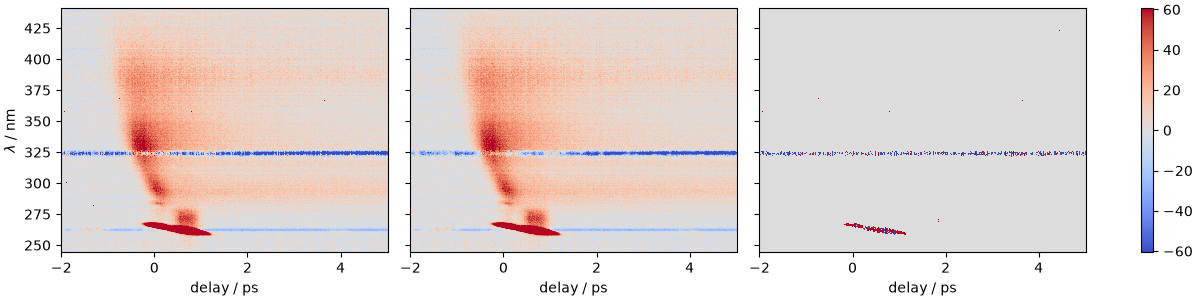

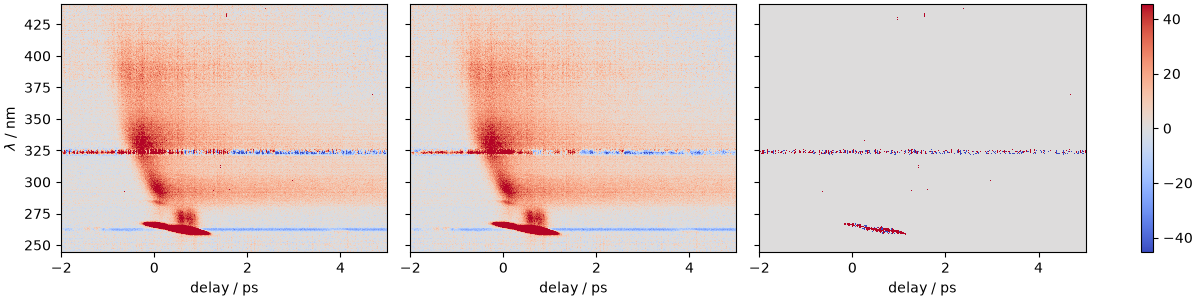

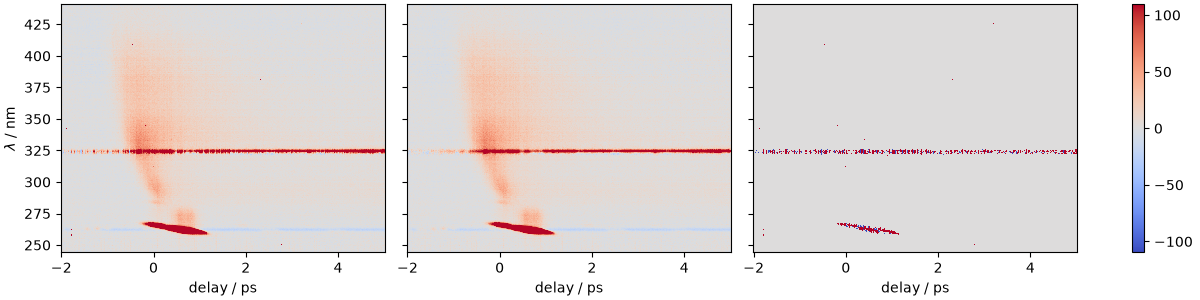

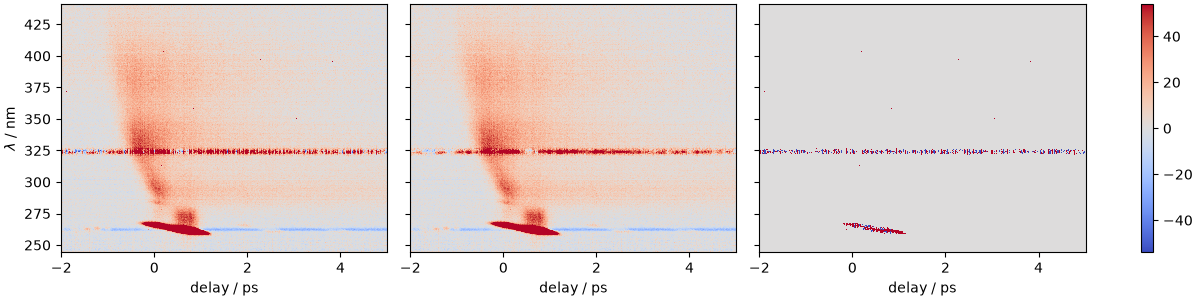

In [11]:
despiked = np.array([despike_median(s, despike_size, threshold=despike_threshold) for s in sig])
for s, d in zip(sig, despiked):
    plot_maps(t, wl_u, [s, d, (s-d)*10], ncols=3)

In [ ]:
avg = avg_scans(subtract_pre_t0(t, despiked, t_bg))
avg = subtract_pre_t0(t, avg, t_pre)

t0_wl, t0 = np.loadtxt(t0_file).T
assert np.allclose(t0_wl, wl_u), "t0 curve sampled on other wavelengths"
t_s, shifted = shift_trace(t, avg, t0)
t_s = t_s - t0_offset

## Effect of the PCF

Both signals are converted to the fluorescence wavelength, per unit of `wl_f`.

In [6]:
pcf_npz = np.load(pcf_file)
pcf_wl, pcf = pcf_npz["wl"], pcf_npz["pcf"].copy()
pcf[~np.isfinite(pcf)] = np.nanmax(pcf)  # choice: undefined values replaced by the maximum

wl_f = fluo_wl(wl_u)  # gate 1340 nm
jac = (np.gradient(wl_u) / np.gradient(wl_f))[:, np.newaxis]  # choice: numerical Jacobian
s = shifted * jac
s_pcf = pcf_correct(wl_u, shifted, pcf_wl, pcf) * jac

In [26]:
Overlay({"no PCF": (t_s, wl_f, s), "PCF": (t_s, wl_f, s_pcf)},
        mode="spectra", ylabel="counts").show()